In [2]:
import os

# Create directory for MRI data
os.makedirs("mri_data", exist_ok=True)

# Download Brain Tumor MRI Dataset from Kaggle
!kaggle datasets download -d masoudnickparvar/brain-tumor-mri-dataset
!unzip -q brain-tumor-mri-dataset.zip -d mri_data/

print("MRI Dataset extracted successfully!")

Dataset URL: https://www.kaggle.com/datasets/masoudnickparvar/brain-tumor-mri-dataset
License(s): Attribution 4.0 International (CC BY 4.0)
100% 157M/157M [00:02<00:00, 78.1MB/s]

MRI Dataset extracted successfully!


In [3]:
import pandas as pd
import glob

# Create lists of files and their categories
file_paths = glob.glob('mri_data/**/*.jpg', recursive=True)

data = []
for path in file_paths:
    parts = path.split(os.sep)
    # Expected path format: mri_data/{Training|Testing}/{Class_Name}/{File_Name}.jpg
    if len(parts) >= 4:
        dataset_split = parts[1]
        label = parts[2]
        data.append({"file_path": path, "split": dataset_split, "label": label})

# Construct the DataFrame
df = pd.DataFrame(data)

print("Dataset Shape:", df.shape)
display(df.head())

Dataset Shape: (7200, 3)


,file_path,split,label
0,mri_data/Training/pituitary/Tr-pi_641.jpg,Training,pituitary
1,mri_data/Training/pituitary/Tr-pi_232.jpg,Training,pituitary
2,mri_data/Training/pituitary/Tr-pi_1061.jpg,Training,pituitary
3,mri_data/Training/pituitary/Tr-pi_1049.jpg,Training,pituitary
4,mri_data/Training/pituitary/Tr-pi_829.jpg,Training,pituitary


In [6]:
print(df.head(3))

                                    file_path     split      label
0   mri_data/Training/pituitary/Tr-pi_641.jpg  Training  pituitary
1   mri_data/Training/pituitary/Tr-pi_232.jpg  Training  pituitary
2  mri_data/Training/pituitary/Tr-pi_1061.jpg  Training  pituitary


In [7]:
df.columns

Index(['file_path', 'split', 'label'], dtype='object')

In [8]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7200 entries, 0 to 7199
Data columns (total 3 columns):
 #   Column     Non-Null Count  Dtype 
---  ------     --------------  ----- 
 0   file_path  7200 non-null   object
 1   split      7200 non-null   object
 2   label      7200 non-null   object
dtypes: object(3)
memory usage: 168.9+ KB


In [9]:
df.describe()

,file_path,split,label
count,7200,7200,7200
unique,7200,2,4
top,mri_data/Testing/notumor/Te-no_4.jpg,Training,pituitary
freq,1,5600,1800


In [10]:
# Check the distribution of the target labels (last column)
print(df.iloc[:, -1].value_counts())

label
pituitary     1800
glioma        1800
meningioma    1800
notumor       1800
Name: count, dtype: int64


In [11]:
df.isnull().sum()

,0
file_path,0
split,0
label,0


```markdown
## Exploratory Data Analysis (EDA)
Let's analyze the distribution of classes, dataset splits, and visualize some sample MRI images from each category.
```

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
import cv2
import random

# Set style
sns.set_theme(style="whitegrid")

# 1. Visualize class distributions split by Train vs Test
plt.figure(figsize=(10, 5))
sns.countplot(data=df, x='label', hue='split', palette='pastel')
plt.title("Class Distribution across Training and Testing Splits")
plt.xlabel("Class Label")
plt.ylabel("Count")
plt.legend(title="Dataset Split")
plt.tight_layout()
plt.show()

```markdown
Now, let's look at representative samples from each of the four categories to understand what our model is learning to classify.
```

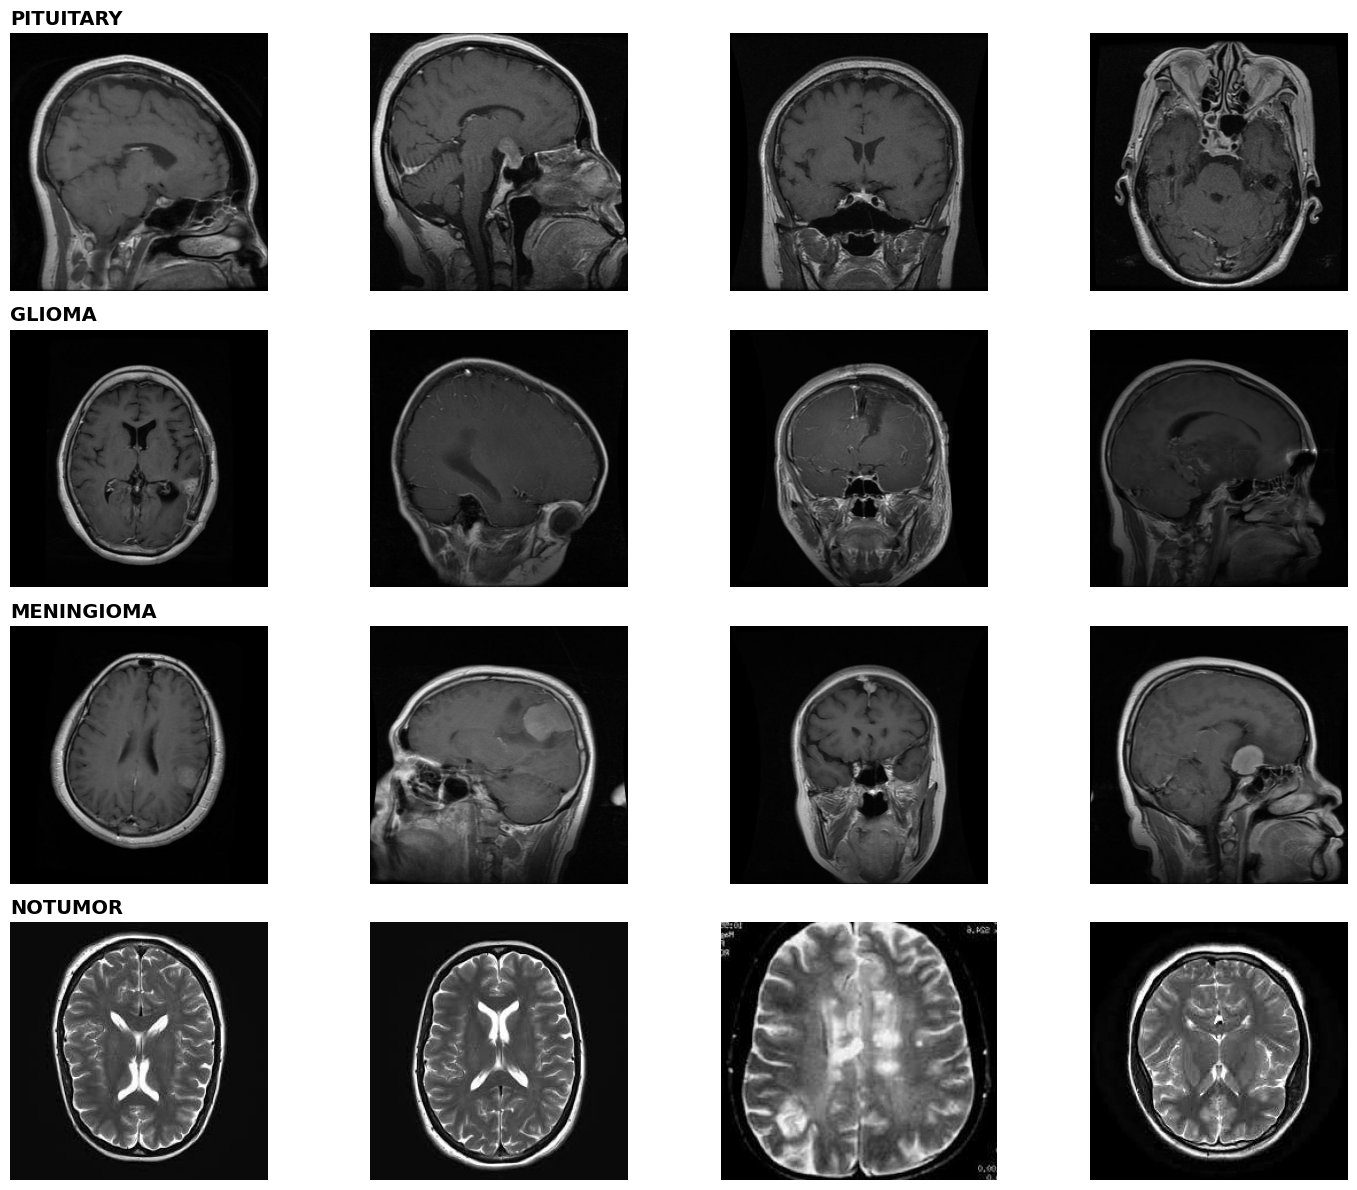

In [16]:
import matplotlib.pyplot as plt
import cv2

# 2. Display sample images from each class
classes = df['label'].unique()
fig, axes = plt.subplots(len(classes), 4, figsize=(15, 12))

for i, cls in enumerate(classes):
    class_df = df[df['label'] == cls]
    samples = class_df.sample(4, random_state=42).reset_index(drop=True)

    for j in range(4):
        img_path = samples.loc[j, 'file_path']
        img = cv2.imread(img_path)
        img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

        axes[i, j].imshow(img)
        axes[i, j].axis('off')
        if j == 0:
            axes[i, j].set_title(f"{cls.upper()}", fontsize=14, loc='left', fontweight='bold')

plt.tight_layout()
plt.show()

```markdown
## Advanced Dataset & Model Visualizations

Let's add more detailed graphical representations:
1. **Class Proportions (Pie Chart)** to see the overall dataset balance.
2. **Image Intensity Histograms** to inspect the pixel distribution across different tumor classes.
```

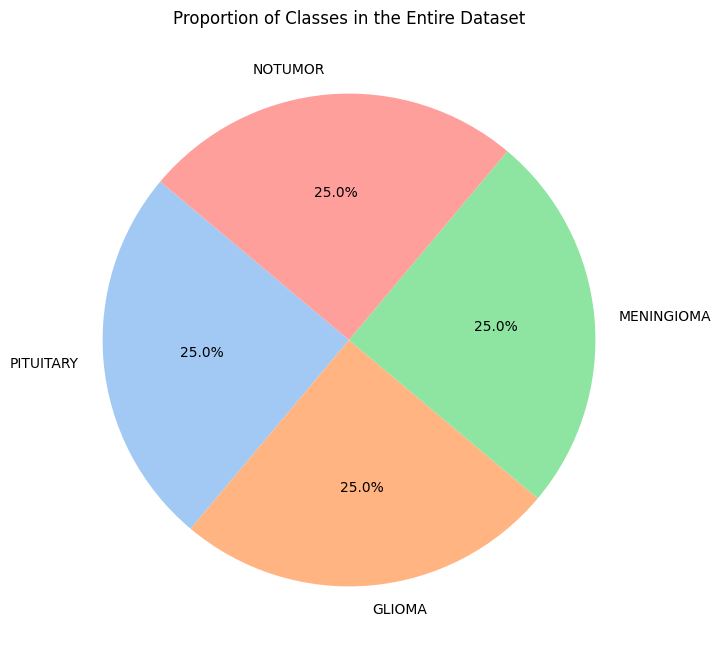

In [17]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import cv2

# 1. Pie Chart of Class Proportions
plt.figure(figsize=(8, 8))
class_counts = df['label'].value_counts()
plt.pie(class_counts, labels=[label.upper() for label in class_counts.index], autopct='%1.1f%%', startangle=140, colors=sns.color_palette('pastel'))
plt.title("Proportion of Classes in the Entire Dataset")
plt.show()

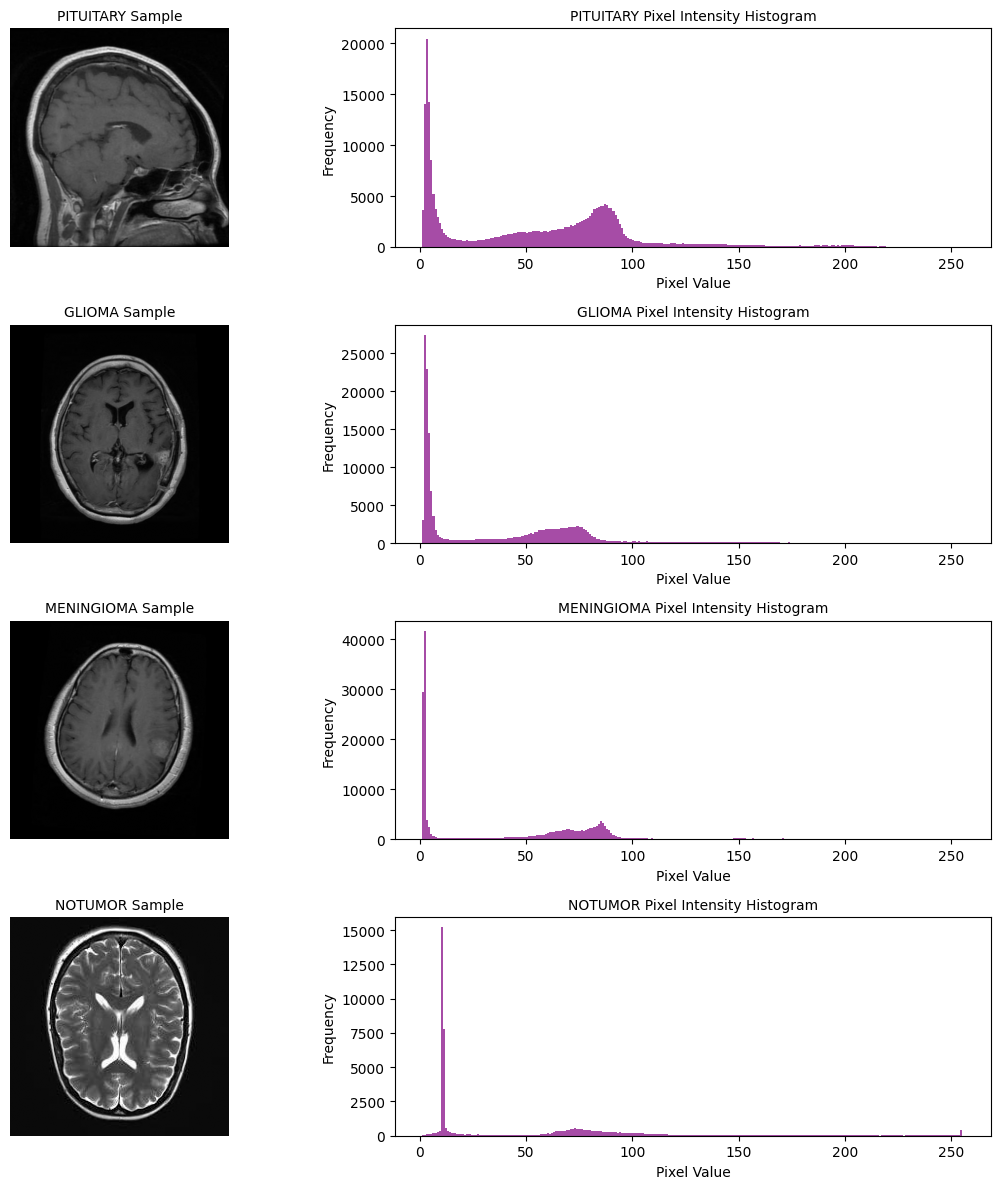

In [18]:
# 2. Pixel Intensity Histograms for Each Class
fig, axes = plt.subplots(len(classes), 2, figsize=(12, 12))

for i, cls in enumerate(classes):
    class_df = df[df['label'] == cls]
    sample_path = class_df.sample(1, random_state=42).iloc[0]['file_path']

    # Read grayscale image for simple intensity profiling
    img = cv2.imread(sample_path, cv2.IMREAD_GRAYSCALE)

    # Display Image
    axes[i, 0].imshow(img, cmap='gray')
    axes[i, 0].set_title(f"{cls.upper()} Sample", fontsize=10)
    axes[i, 0].axis('off')

    # Display Histogram
    axes[i, 1].hist(img.ravel(), bins=256, color='purple', alpha=0.7, range=[1, 256]) # Skip 0 (background)
    axes[i, 1].set_title(f"{cls.upper()} Pixel Intensity Histogram", fontsize=10)
    axes[i, 1].set_xlabel("Pixel Value")
    axes[i, 1].set_ylabel("Frequency")

plt.tight_layout()
plt.show()

In [8]:
import os
import tensorflow as tf
from tensorflow.keras import layers, models
from tensorflow.keras.applications import MobileNetV2
from tensorflow.keras.preprocessing.image import ImageDataGenerator

# 1. Hyperparameters & Settings
IMG_SIZE = (224, 224)
BATCH_SIZE = 32
EPOCHS = 15

TRAIN_DIR = "mri_data/Training"
TEST_DIR = "mri_data/Testing"

# 2. Data Augmentation & Generators
train_datagen = ImageDataGenerator(
    rescale=1./255,
    rotation_range=15,
    width_shift_range=0.1,
    height_shift_range=0.1,
    horizontal_flip=True,
    validation_split=0.2
)

test_datagen = ImageDataGenerator(rescale=1./255)

train_generator = train_datagen.flow_from_directory(
    TRAIN_DIR,
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode='categorical',
    subset='training'
)

val_generator = train_datagen.flow_from_directory(
    TRAIN_DIR,
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode='categorical',
    subset='validation'
)

test_generator = test_datagen.flow_from_directory(
    TEST_DIR,
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode='categorical',
    shuffle=False
)

# 3. Model Architecture using Transfer Learning (MobileNetV2)
base_model = MobileNetV2(weights='imagenet', include_top=False, input_shape=(224, 224, 3))
base_model.trainable = False  # Freeze pre-trained weights for fast feature extraction

model_mri = models.Sequential([
    base_model,
    layers.GlobalAveragePooling2D(),
    layers.BatchNormalization(),
    layers.Dense(256, activation='relu'),
    layers.Dropout(0.4),
    layers.Dense(4, activation='softmax')  # 4 classes: Glioma, Meningioma, Pituitary, No Tumor
])

model_mri.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

model_mri.summary()

# 4. Train the MRI Branch
callbacks = [
    tf.keras.callbacks.ModelCheckpoint("models/neurosense_mri_best.keras", save_best_only=True, monitor='val_accuracy'),
    tf.keras.callbacks.EarlyStopping(monitor='val_loss', patience=4, restore_best_weights=True)
]

history = model_mri.fit(
    train_generator,
    validation_data=val_generator,
    epochs=EPOCHS,
    callbacks=callbacks
)

# 5. Evaluate on Test Set
test_loss, test_acc = model_mri.evaluate(test_generator)
print(f"\nTest Accuracy for MRI Branch: {test_acc * 100:.2f}%")

Found 4480 images belonging to 4 classes.
Found 1120 images belonging to 4 classes.
Found 1600 images belonging to 4 classes.
9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 1280)           │         5,120 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 256)            │       327,936 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 4)              │         1,028 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,592,068 (9.89 MB)

 Trainable params: 331,524 (1.26 MB)

 Non-trainable params: 2,260,544 (8.62 MB)

Epoch 1/15
140/140 ━━━━━━━━━━━━━━━━━━━━ 89s 541ms/step - accuracy: 0.8154 - loss: 0.5521 - val_accuracy: 0.8938 - val_loss: 0.3025
Epoch 2/15
140/140 ━━━━━━━━━━━━━━━━━━━━ 75s 533ms/step - accuracy: 0.8795 - loss: 0.3408 - val_accuracy: 0.9196 - val_loss: 0.2374
Epoch 3/15
140/140 ━━━━━━━━━━━━━━━━━━━━ 72s 513ms/step - accuracy: 0.9083 - loss: 0.2412 - val_accuracy: 0.9143 - val_loss: 0.2146
Epoch 4/15
140/140 ━━━━━━━━━━━━━━━━━━━━ 85s 611ms/step - accuracy: 0.9212 - loss: 0.2163 - val_accuracy: 0.9241 - val_loss: 0.2142
Epoch 5/15
140/140 ━━━━━━━━━━━━━━━━━━━━ 76s 541ms/step - accuracy: 0.9257 - loss: 0.1970 - val_accuracy: 0.9411 - val_loss: 0.1765
Epoch 6/15
140/140 ━━━━━━━━━━━━━━━━━━━━ 73s 525ms/step - accuracy: 0.9339 - loss: 0.1792 - val_accuracy: 0.9375 - val_loss: 0.1991
Epoch 7/15
140/140 ━━━━━━━━━━━━━━━━━━━━ 72s 518ms/step - accuracy: 0.9422 - loss: 0.1527 - val_accuracy: 0.9455 - val_loss: 0.1597
Epoch 8/15
140/140 ━━━━━━━━━━━━━━━━━━━━ 71s 505ms/step - accuracy: 0.9498 - loss: 0

```markdown
## Strategy to Improve Accuracy: Fine-Tuning

Now that we have trained a baseline model using transfer learning (where the entire `MobileNetV2` feature extractor was frozen), we can improve the accuracy by:
1. Unfreezing the top layers of `MobileNetV2` (e.g., the last 50 layers).
2. Recompiling the model with a **much lower learning rate** (e.g., `1e-5` instead of `1e-3`) to prevent breaking the pre-trained weights.
3. Training for more epochs with early stopping to let the model adapt to specific MRI patterns.
```

In [9]:
# 1. Unfreeze the base model to allow fine-tuning
base_model.trainable = True

# Let's see how many layers are in the base model
print(f"Number of layers in base model: {len(base_model.layers)}")

# Fine-tune from this layer onwards (freeze everything before it)
# We'll freeze the first 100 layers and unfreeze the rest
fine_tune_at = 100

for layer in base_model.layers[:fine_tune_at]:
    layer.trainable = False

# 2. Recompile the model with a very low learning rate
model_mri.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-5),  # Low learning rate for fine-tuning
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

model_mri.summary()

Number of layers in base model: 154


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 1280)           │         5,120 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 256)            │       327,936 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 4)              │         1,028 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,592,068 (9.89 MB)

 Trainable params: 2,192,964 (8.37 MB)

 Non-trainable params: 399,104 (1.52 MB)

In [10]:
# 3. Retrain the model (Fine-tuning phase)
fine_tune_epochs = 10
total_epochs = EPOCHS + fine_tune_epochs

# Update early stopping or checkpoints for fine-tuning
callbacks_fine = [
    tf.keras.callbacks.ModelCheckpoint("models/neurosense_mri_finetuned_best.keras", save_best_only=True, monitor='val_accuracy'),
    tf.keras.callbacks.EarlyStopping(monitor='val_loss', patience=3, restore_best_weights=True)
]

history_fine = model_mri.fit(
    train_generator,
    validation_data=val_generator,
    epochs=total_epochs,
    initial_epoch=history.epoch[-1] if 'history' in globals() else 15,
    callbacks=callbacks_fine
)

# 4. Evaluate the fine-tuned model
test_loss_fine, test_acc_fine = model_mri.evaluate(test_generator)
print(f"\nTest Accuracy after Fine-Tuning: {test_acc_fine * 100:.2f}%")

Epoch 13/25
140/140 ━━━━━━━━━━━━━━━━━━━━ 101s 558ms/step - accuracy: 0.8058 - loss: 0.6060 - val_accuracy: 0.9107 - val_loss: 0.2834
Epoch 14/25
140/140 ━━━━━━━━━━━━━━━━━━━━ 74s 526ms/step - accuracy: 0.8685 - loss: 0.3958 - val_accuracy: 0.8875 - val_loss: 0.3541
Epoch 15/25
140/140 ━━━━━━━━━━━━━━━━━━━━ 72s 514ms/step - accuracy: 0.8951 - loss: 0.3034 - val_accuracy: 0.9062 - val_loss: 0.2957
Epoch 16/25
140/140 ━━━━━━━━━━━━━━━━━━━━ 72s 511ms/step - accuracy: 0.9025 - loss: 0.2753 - val_accuracy: 0.9241 - val_loss: 0.2309
Epoch 17/25
140/140 ━━━━━━━━━━━━━━━━━━━━ 73s 523ms/step - accuracy: 0.9163 - loss: 0.2214 - val_accuracy: 0.9179 - val_loss: 0.2371
Epoch 18/25
140/140 ━━━━━━━━━━━━━━━━━━━━ 74s 528ms/step - accuracy: 0.9312 - loss: 0.1905 - val_accuracy: 0.9321 - val_loss: 0.2204
Epoch 19/25
140/140 ━━━━━━━━━━━━━━━━━━━━ 72s 514ms/step - accuracy: 0.9312 - loss: 0.1889 - val_accuracy: 0.9339 - val_loss: 0.1981
Epoch 20/25
140/140 ━━━━━━━━━━━━━━━━━━━━ 72s 513ms/step - accuracy: 0.9393 

```markdown
## Detailed Model Evaluation

Let's generate graphical representations of our fine-tuned model's performance on the test set:
1. **Confusion Matrix** to see exactly which classes are being confused with each other.
2. **Classification Report Heatmap** showing precision, recall, and f1-score per class.
```

50/50 ━━━━━━━━━━━━━━━━━━━━ 8s 85ms/step


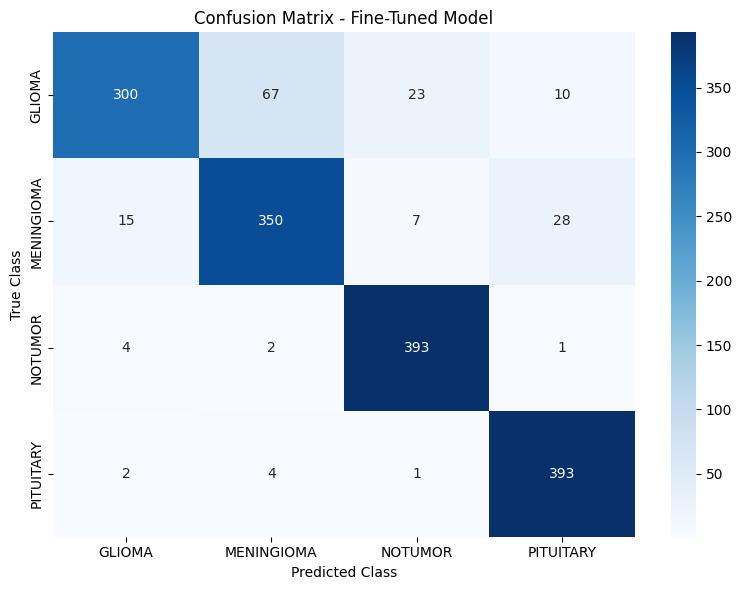

In [11]:
from sklearn.metrics import confusion_matrix, classification_report
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np

# 1. Get predictions on the test generator
test_generator.reset()
Y_pred = model_mri.predict(test_generator)
y_pred = np.argmax(Y_pred, axis=1)
y_true = test_generator.classes
class_names = list(test_generator.class_indices.keys())

# 2. Compute Confusion Matrix
cm = confusion_matrix(y_true, y_pred)

plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=[c.upper() for c in class_names],
            yticklabels=[c.upper() for c in class_names])
plt.title('Confusion Matrix - Fine-Tuned Model')
plt.ylabel('True Class')
plt.xlabel('Predicted Class')
plt.tight_layout()
plt.show()

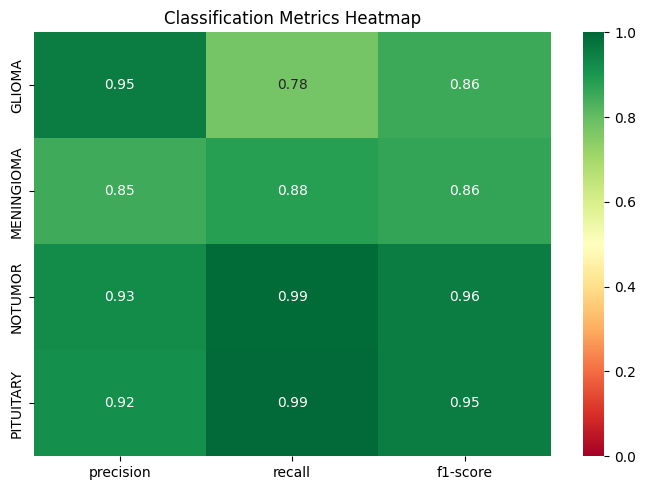

In [20]:
# 3. Visual Classification Report
report = classification_report(y_true, y_pred, target_names=[c.upper() for c in class_names], output_dict=True)
report_df = pd.DataFrame(report).iloc[:-1, :-3].T  # Exclude support and averages for a clean heatmap

plt.figure(figsize=(7, 5))
sns.heatmap(report_df, annot=True, cmap='RdYlGn', vmin=0.0, vmax=1.0)
plt.title('Classification Metrics Heatmap')
plt.tight_layout()
plt.show()

```markdown
## Training & Fine-Tuning History Curves
Let's plot the training and validation accuracy and loss over all epochs to visualize the learning curves and identify any overfitting.
```

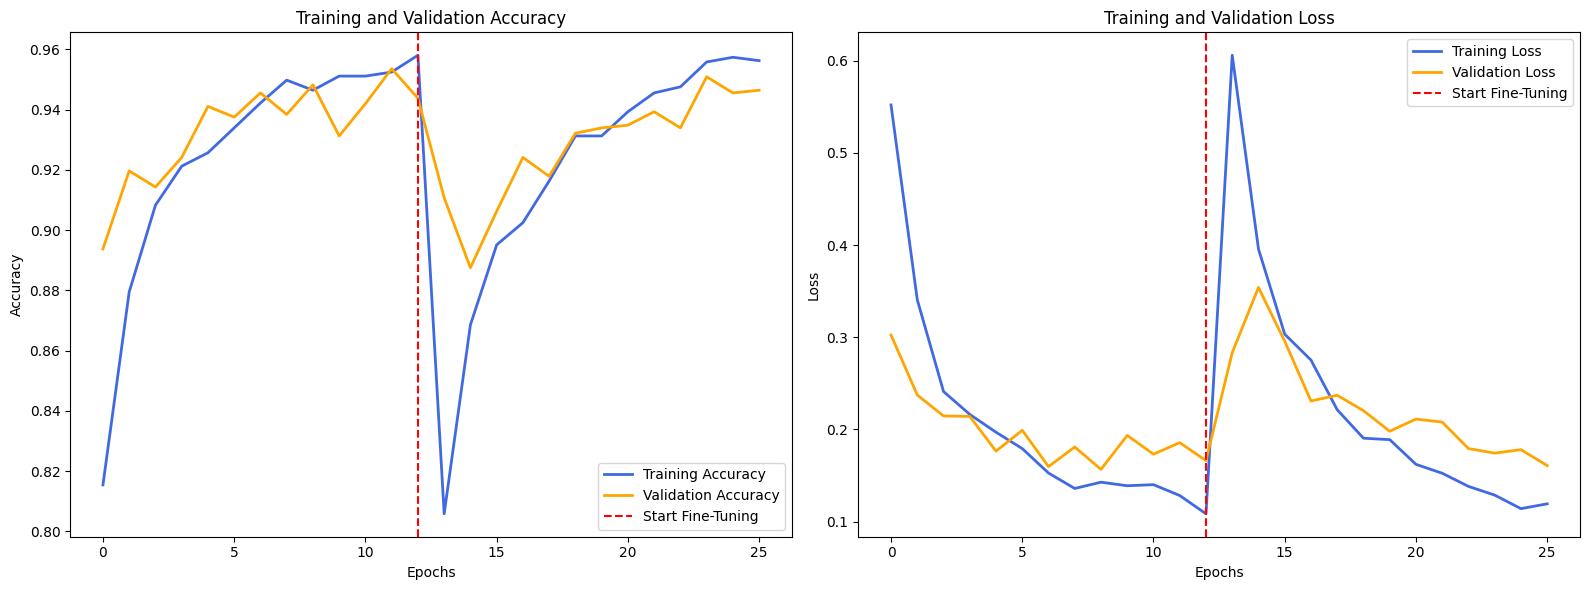

In [12]:
import matplotlib.pyplot as plt

# Combine history from initial training and fine-tuning if available
acc = []
val_acc = []
loss = []
val_loss = []

if 'history' in globals():
    acc += history.history['accuracy']
    val_acc += history.history['val_accuracy']
    loss += history.history['loss']
    val_loss += history.history['val_loss']

if 'history_fine' in globals():
    acc += history_fine.history['accuracy']
    val_acc += history_fine.history['val_accuracy']
    loss += history_fine.history['loss']
    val_loss += history_fine.history['val_loss']

epochs_range = range(len(acc))

plt.figure(figsize=(16, 6))

# Plot Training and Validation Accuracy
plt.subplot(1, 2, 1)
plt.plot(epochs_range, acc, label='Training Accuracy', color='royalblue', lw=2)
plt.plot(epochs_range, val_acc, label='Validation Accuracy', color='orange', lw=2)
if 'history_fine' in globals() and 'history' in globals():
    plt.axvline(x=len(history.history['accuracy'])-1, color='red', linestyle='--', label='Start Fine-Tuning')
plt.title('Training and Validation Accuracy')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend(loc='lower right')

# Plot Training and Validation Loss
plt.subplot(1, 2, 2)
plt.plot(epochs_range, loss, label='Training Loss', color='royalblue', lw=2)
plt.plot(epochs_range, val_loss, label='Validation Loss', color='orange', lw=2)
if 'history_fine' in globals() and 'history' in globals():
    plt.axvline(x=len(history.history['accuracy'])-1, color='red', linestyle='--', label='Start Fine-Tuning')
plt.title('Training and Validation Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend(loc='upper right')

plt.tight_layout()
plt.show()

```markdown
## Visualizing Predictions & High-Dimensional Feature Space
Let's add deeper analytical representations:
1. **Model Prediction Grid**: Visually inspecting correct vs. incorrect predictions on actual test images.
2. **t-SNE Feature Clustering**: Visualizing how the neural network groups the 4 different classes in its latent space.
```

1/1 ━━━━━━━━━━━━━━━━━━━━ 3s 3s/step


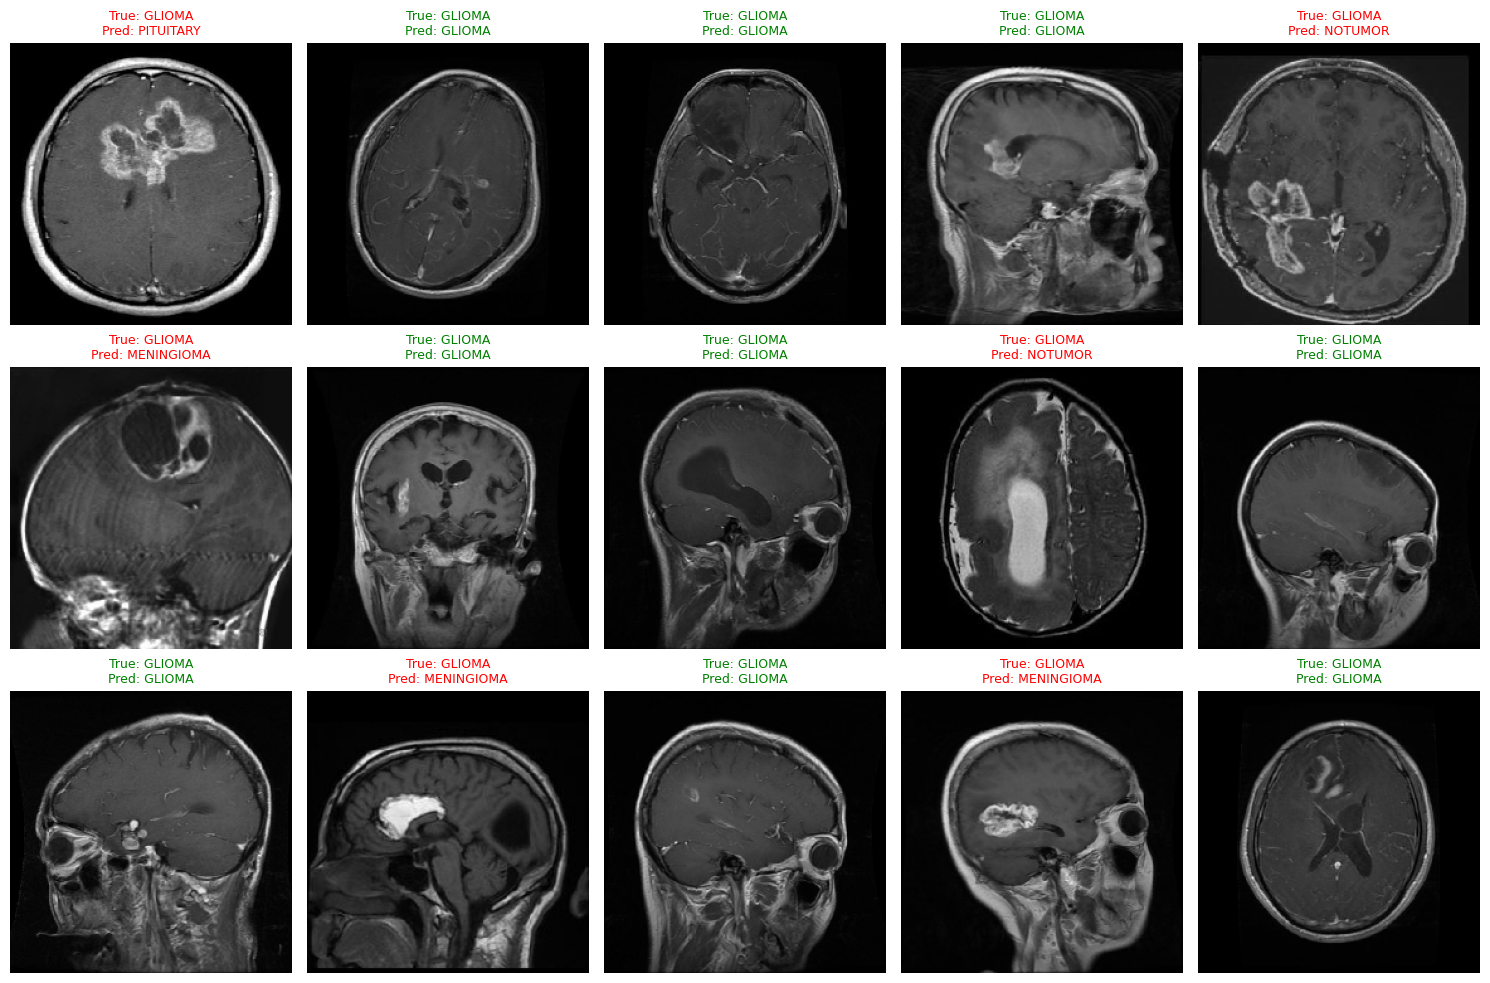

In [13]:
# 1. Visual Prediction Grid on Test Set Samples
import matplotlib.pyplot as plt
import numpy as np

test_generator.reset()
x_batch, y_batch = next(test_generator)
preds = model_mri.predict(x_batch)

plt.figure(figsize=(15, 10))
for i in range(15):
    plt.subplot(3, 5, i+1)
    plt.imshow(x_batch[i])

    true_label = class_names[np.argmax(y_batch[i])].upper()
    pred_label = class_names[np.argmax(preds[i])].upper()

    color = 'green' if true_label == pred_label else 'red'

    plt.title(f"True: {true_label}\nPred: {pred_label}", color=color, fontsize=9)
    plt.axis('off')

plt.tight_layout()
plt.show()

/usr/local/lib/python3.13/dist-packages/sklearn/manifold/_t_sne.py:1164: FutureWarning: 'n_iter' was renamed to 'max_iter' in version 1.5 and will be removed in 1.7.
  warnings.warn(


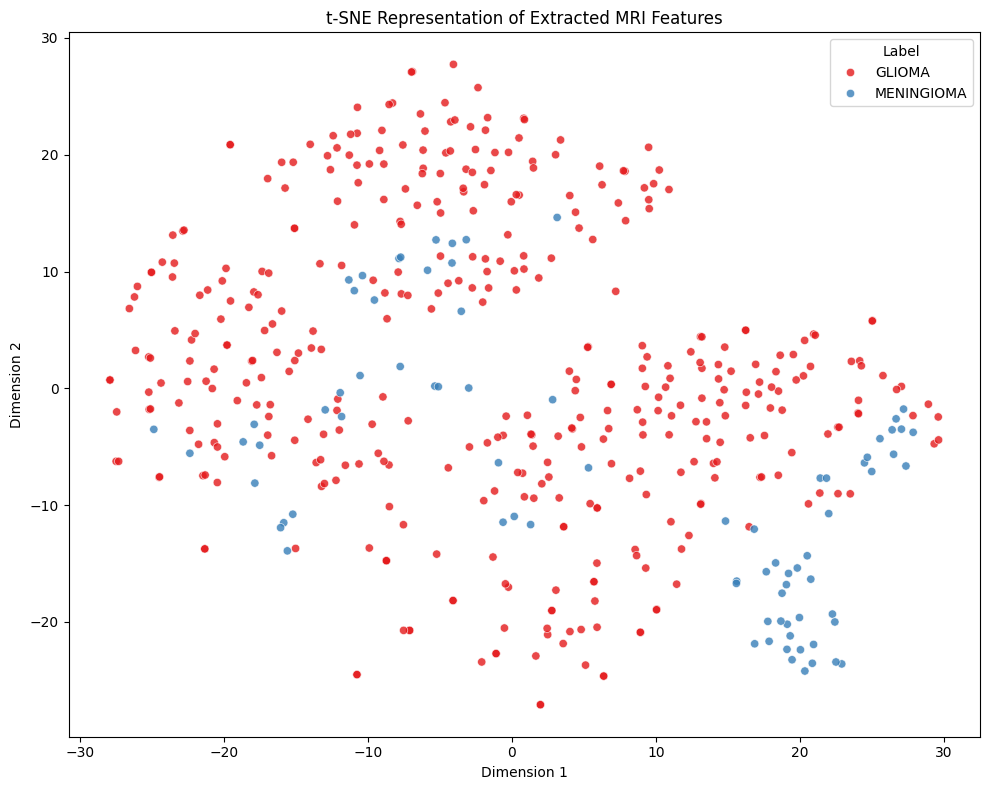

In [22]:
# 2. t-SNE Dimensionality Reduction Visualization on Extracted Features
from sklearn.manifold import TSNE
import pandas as pd
import seaborn as sns
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf

# Extract features by directly passing batches through the base pre-trained model
# This completely bypasses Keras functional API shape-binding errors

test_generator.reset()
features = []
labels = []

for i in range(len(test_generator)):
    x, y = next(test_generator)
    # Propagate the images through the base model (MobileNetV2 feature extractor)
    # and pool the spatial dimensions
    base_feats = model_mri.layers[0](x, training=False)
    pooled_feats = tf.keras.layers.GlobalAveragePooling2D()(base_feats).numpy()

    features.append(pooled_feats)
    labels.append(np.argmax(y, axis=1))
    if len(features) >= 15:  # Limit to 15 batches for quick computation
        break

features = np.concatenate(features, axis=0)
labels = np.concatenate(labels, axis=0)

# Compute t-SNE
tsne = TSNE(n_components=2, random_state=42, perplexity=30, n_iter=500)
tsne_results = tsne.fit_transform(features)

# Plot the distribution in latent space
tsne_df = pd.DataFrame(tsne_results, columns=['Dimension 1', 'Dimension 2'])
tsne_df['Label'] = [class_names[idx].upper() for idx in labels]

plt.figure(figsize=(10, 8))
sns.scatterplot(x='Dimension 1', y='Dimension 2', hue='Label', data=tsne_df, palette='Set1', alpha=0.8)
plt.title('t-SNE Representation of Extracted MRI Features')
plt.tight_layout()
plt.show()

In [16]:
# --- 2. Convert MRI Model ---
mri_model = tf.keras.models.load_model("models/neurosense_mri_best.keras")
converter_mri = tf.lite.TFLiteConverter.from_keras_model(mri_model)
converter_mri.optimizations = [tf.lite.Optimize.DEFAULT]
tflite_mri_model = converter_mri.convert()

with open("models/neurosense_mri.tflite", "wb") as f:
    f.write(tflite_mri_model)
print("MRI TFLite model saved successfully!")

Saved artifact at '/tmp/tmp50xr19w8'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(None, 224, 224, 3), dtype=tf.float32, name='input_layer_1')
Output Type:
  TensorSpec(shape=(None, 4), dtype=tf.float32, name=None)
Captures:
  140545568175888: TensorSpec(shape=(), dtype=tf.resource, name=None)
  140545568176080: TensorSpec(shape=(), dtype=tf.resource, name=None)
  140545568175312: TensorSpec(shape=(), dtype=tf.resource, name=None)
  140545568174160: TensorSpec(shape=(), dtype=tf.resource, name=None)
  140545568175696: TensorSpec(shape=(), dtype=tf.resource, name=None)
  140545568176656: TensorSpec(shape=(), dtype=tf.resource, name=None)
  140545568174544: TensorSpec(shape=(), dtype=tf.resource, name=None)
  140545568173392: TensorSpec(shape=(), dtype=tf.resource, name=None)
  140545568174928: TensorSpec(shape=(), dtype=tf.resource, name=None)
  140545568177040: TensorSpec(shape=(), dtype=tf.resource, name=None)
  1405455681747